# GNN influence and hub test on Kaggle or Colab

Runs `models/explainability/run_gnn.sh` on a GPU: trains DCRNN and Graph WaveNet (fixed adjacency) on a degree-preserving random graph, then runs `influence.py` and `hubs.py` on the real-graph and random-graph models. See `models/explainability/README.md` for what is measured.

Before running:

1. Push the `explainability-analysis` branch. The trained connectome models (`models/stgnn/runs/*/best.pt`) come with the clone.
2. Upload `processed/session_4_7_cave_proofread` (156 MB, not in git). On Kaggle, add it as a dataset. On Colab, put the folder on Google Drive.
3. Turn on a GPU. On Kaggle pick **T4** (recent PyTorch builds do not support the P100) and turn on internet access.
4. If the repository is private, put a GitHub token in the clone URL.

Each finished step is copied to `SAVE_TO`. If the session ends, run the notebook again and finished steps are skipped. On Kaggle, use *Save Version → Save & Run All* so the run continues in the background and `/kaggle/working` is kept.

In [1]:
!find /kaggle/input -name X_features.npy

/kaggle/input/datasets/irenealdabaldetrecu/cave-proofread/X_features.npy


In [2]:
import os

KAGGLE = os.path.exists('/kaggle')
REPO = 'https://github.com/G00DCOD3R/Neural-Forecasting.git'
BRANCH = 'explainability-analysis'
STRIDE = 4  # every 4th test window, as in the README
MODELS = 'dcrnn graph_wavenet'

if KAGGLE:
    DATA = '/kaggle/input/datasets/irenealdabaldetrecu/cave-proofread'  # folder holding X_features.npy, conditions.csv, edge_index.pt, ...
    SAVE_TO = '/kaggle/working/results'
    WORK = '/tmp/Neural-Forecasting'
else:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA = '/content/drive/MyDrive/neural-forecasting/session_4_7_cave_proofread'
    SAVE_TO = '/content/drive/MyDrive/neural-forecasting/results'
    WORK = '/content/Neural-Forecasting'

assert os.path.exists(f'{DATA}/X_features.npy'), f'processed session not found in {DATA}'

In [3]:
# The repository is private: clone with a GitHub token stored as the secret GITHUB_TOKEN
# (Kaggle: Add-ons -> Secrets; Colab: the key icon in the left bar)
if not os.path.exists(WORK):
    if KAGGLE:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret('GITHUB_TOKEN')
    else:
        from google.colab import userdata
        token = userdata.get('GITHUB_TOKEN')
    url = REPO.replace('https://', f'https://{token}@')
    !GIT_TERMINAL_PROMPT=0 git clone --depth 1 -b {BRANCH} {url} {WORK}
    !git -C {WORK} remote set-url origin {REPO}  # do not leave the token in .git/config
os.makedirs(f'{WORK}/processed', exist_ok=True)
if not os.path.exists(f'{WORK}/processed/session_4_7_cave_proofread'):
    os.symlink(DATA, f'{WORK}/processed/session_4_7_cave_proofread')


Cloning into '/tmp/Neural-Forecasting'...
remote: Enumerating objects: 72, done.
remote: Counting objects: 100% (72/72), done.
remote: Compressing objects: 100% (65/65), done.
remote: Total 72 (delta 8), reused 58 (delta 6), pack-reused 0 (from 0)
Receiving objects: 100% (72/72), 5.96 MiB | 38.40 MiB/s, done.
Resolving deltas: 100% (8/8), done.


Same versions as `models/stgnn/requirements.txt` (torch < 2.13), with CUDA 12.6.

In [4]:
!pip install -q torch==2.12.1 --index-url https://download.pytorch.org/whl/cu126
!pip install -q torch-scatter torch-sparse -f https://data.pyg.org/whl/torch-2.12.1+cu126.html
!pip install -q torch-geometric torch-spatiotemporal
!python -c "import torch, tsl; print(torch.__version__, tsl.__version__, 'cuda', torch.cuda.is_available())"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchvision 0.26.0+cu128 requires torch==2.11.0, but you have torch 2.12.1+cu126 which is incompatible.
2.12.1+cu126 0.9.5 cuda True


Bring back steps finished in an earlier session, then run everything that is missing.

In [5]:
if os.path.exists(SAVE_TO):
    !cp -rn {SAVE_TO}/. {WORK}/models/
!cd {WORK} && SAVE_TO={SAVE_TO} STRIDE={STRIDE} bash models/explainability/run_gnn.sh {MODELS}

dcrnn params=39585 windows train/val/test 21568/4602/4710 device=cuda
epoch   1  train 0.4988  val 0.3767
epoch   2  train 0.4461  val 0.3394
epoch   3  train 0.4111  val 0.3191
epoch   4  train 0.3958  val 0.3119
epoch   5  train 0.3897  val 0.3084
epoch   6  train 0.3864  val 0.3076
epoch   7  train 0.3842  val 0.3049
epoch   8  train 0.3825  val 0.3044
epoch   9  train 0.3811  val 0.3029
epoch  10  train 0.3802  val 0.3023
epoch  11  train 0.3792  val 0.3016
epoch  12  train 0.3785  val 0.3017
epoch  13  train 0.3779  val 0.3007
epoch  14  train 0.3772  val 0.3007
epoch  15  train 0.3769  val 0.3002
epoch  16  train 0.3765  val 0.2997
epoch  17  train 0.3757  val 0.2993
epoch  18  train 0.3755  val 0.3002
epoch  19  train 0.3752  val 0.3004
epoch  20  train 0.3748  val 0.3021
epoch  21  train 0.3744  val 0.2991
epoch  22  train 0.3742  val 0.2988
epoch  23  train 0.3739  val 0.2982
epoch  24  train 0.3736  val 0.2998
epoch  25  train 0.3734  val 0.2974
epoch  26  train 0.3732  val 0

dcrnn: top-20% share 55.1% [52.3%, 60.1%], random graph 55.7%, out-degree 41.9%, evidence for hubs: False


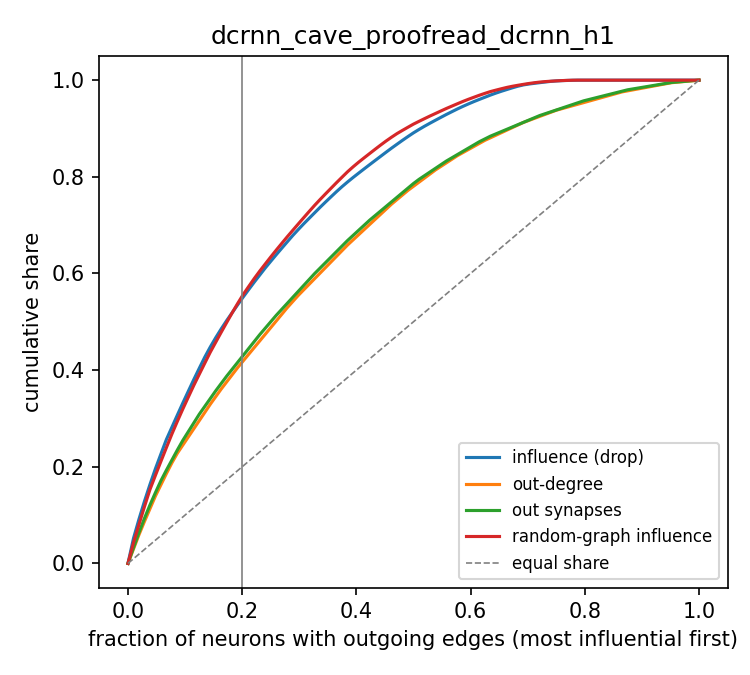

In [6]:
import json
from IPython.display import Image, display

for model, tag in [('dcrnn', 'dcrnn'), ('graph_wavenet', 'gwn_fixed')]:
    out = f'{WORK}/models/explainability/runs/{model}_cave_proofread_{tag}_h1'
    if not os.path.exists(f'{out}/hubs.json'):
        continue
    h = json.load(open(f'{out}/hubs.json'))
    c = h['concentration']
    print(f"{model}: top-20% share {c['influence_drop'][0]:.1%} [{c['influence_drop'][1]:.1%}, {c['influence_drop'][2]:.1%}], "
          f"random graph {c['null_influence_drop'][0]:.1%}, out-degree {c['wiring_out_degree']:.1%}, "
          f"evidence for hubs: {h['evidence_for_hubs']}")
    display(Image(f'{out}/concentration.png', width=400))

Download `SAVE_TO` and copy its contents into `models/` in your local repository (it holds `stgnn/runs/*_rewired_h1` and `explainability/runs/*`).